#Task 1 Approach 2
# Using ALBERT+TextCNN approach

Load Training and Validation data into pandas Dataframes

In [1]:
import pandas as pd

# Mount Google Drive (if not already mounted)
from google.colab import drive
drive.mount('/content/drive')

# File paths
train_path = "/content/drive/My Drive/ANLE/Assignment Datasets/propaganda_train.tsv"
val_path = "/content/drive/My Drive/ANLE/Assignment Datasets/propaganda_val.tsv"

# Read the TSV files into DataFrames
train_df_raw = pd.read_csv(train_path, sep='\t')
val_df_raw = pd.read_csv(val_path, sep='\t')

Mounted at /content/drive


## Data Preprocessing

####Remove Tags, extract the spans/snippets, and remove non-propaganda sentences

In [2]:
import re

# Remove tags as they are not useful for this approach
def clean_text(text):
    return text.replace('<BOS>', '').replace('<EOS>', '').strip()

# extract only spans for propaganda sentences
def extract_span(text):
    match = re.search(r'<BOS>(.*?)<EOS>', text)
    return match.group(1).strip() if match else ""


# Rebuild train_df
train_df = pd.DataFrame({
    'context': train_df_raw['tagged_in_context'].apply(clean_text),
    'span': train_df_raw['tagged_in_context'].apply(extract_span),
    'label': train_df_raw['label']
})

# Same for val_df
val_df = pd.DataFrame({
    'context': val_df_raw['tagged_in_context'].apply(clean_text),
    'span': val_df_raw['tagged_in_context'].apply(extract_span),
    'label': val_df_raw['label']
})

print(f"Shapes before removing 'not propaganda'. Train Shape: {train_df.shape}, Val Shape: {val_df.shape}")

# Filter out "not propaganda"
train_df = train_df[train_df['label'] != 'not_propaganda'].reset_index(drop=True)
val_df = val_df[val_df['label'] != 'not_propaganda'].reset_index(drop=True)

print(f"Shapes after removing 'not propaganda'. Train Shape: {train_df.shape}, Val Shape: {val_df.shape}")

Shapes before removing 'not propaganda'. Train Shape: (2414, 3), Val Shape: (580, 3)
Shapes after removing 'not propaganda'. Train Shape: (1223, 3), Val Shape: (279, 3)


In [3]:
# Combining span and contetx together for training and validation
def combine_texts(row):
    return row['span'] + " " + row['context']

train_df['combined'] = train_df.apply(combine_texts, axis=1)
val_df['combined'] = val_df.apply(combine_texts, axis=1)

####Encode Labels

In [4]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Encode labels into integers
le = LabelEncoder()
train_df['label_encoded'] = le.fit_transform(train_df['label'])
val_df['label_encoded'] = le.transform(val_df['label'])  # use same encoder

####Split validation data into validation and tet data 50/50

In [5]:
# Split val_df into two DataFrames
val_df_new, test_df = train_test_split(
    val_df,
    test_size=0.5,
    stratify=val_df['label_encoded'],  # insures class balance in splits
    random_state=42
)

# Reset index (optional but nice for clean iteration)
val_df = val_df_new.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

In [6]:
print(f"Train Shape: {train_df.shape}, Val Shape: {val_df.shape}, Test Shape: {test_df.shape}")
test_df.head(20)

Train Shape: (1223, 5), Val Shape: (139, 5), Test Shape: (140, 5)


,context,span,label,combined,label_encoded
0,“The reluctance of some in the Vatican Curia t...,“The reluctance of some in the Vatican Curia t...,appeal_to_fear_prejudice,“The reluctance of some in the Vatican Curia t...,0
1,We are supposed to serve as an example to the ...,We are supposed to serve as an example to the ...,flag_waving,We are supposed to serve as an example to the ...,4
2,She also admits the election result was a “los...,another indication that Google’s efforts were ...,doubt,another indication that Google’s efforts were ...,2
3,"“I must, in the strongest of terms, ask Mexico...",OUR SOUTHERN BORDER!”,flag_waving,"OUR SOUTHERN BORDER!” “I must, in the stronges...",4
4,Conservatives need to remember that the purpos...,"the Left’s frenzied, demagogic assault","name_calling,labeling","the Left’s frenzied, demagogic assault Conserv...",6
5,“..This is a terrible situation and Attorney ...,Attorney General Jeff Sessions should stop thi...,flag_waving,Attorney General Jeff Sessions should stop thi...,4
6,"First the Dems demanded that Ford, a long-ti...",the Dems,repetition,"the Dems First the Dems demanded that Ford, ...",7
7,Maybe he should have taken the time to look to...,Maybe he should have taken the time to look to...,flag_waving,Maybe he should have taken the time to look to...,4
8,"Trump was, unfortunately, following the exampl...",severely misleading the American people,flag_waving,severely misleading the American people Trump ...,4
9,It’s the very reason the governments of the wo...,It’s the very reason the governments of the wo...,causal_oversimplification,It’s the very reason the governments of the wo...,1


## Convert tokens into dynamic Embeddings with BERT

In [7]:
import torch
from transformers import AlbertTokenizer, AlbertModel

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load tokenizer and model
tokenizer = AlbertTokenizer.from_pretrained('albert-base-v2')
albert = AlbertModel.from_pretrained('albert-base-v2').to(device)
albert.eval()  # Set model to eval mode (no dropout, etc.)

Using device: cuda


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/47.4M [00:00<?, ?B/s]

AlbertModel(
  (embeddings): AlbertEmbeddings(
    (word_embeddings): Embedding(30000, 128, padding_idx=0)
    (position_embeddings): Embedding(512, 128)
    (token_type_embeddings): Embedding(2, 128)
    (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0, inplace=False)
  )
  (encoder): AlbertTransformer(
    (embedding_hidden_mapping_in): Linear(in_features=128, out_features=768, bias=True)
    (albert_layer_groups): ModuleList(
      (0): AlbertLayerGroup(
        (albert_layers): ModuleList(
          (0): AlbertLayer(
            (full_layer_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (attention): AlbertSdpaAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (attention_dropout): Dropout(p=0, inplace=False)
  

####Tokinize sentences with tokenizer

In [8]:
# Tokenization function
def tokenize_texts(texts, tokenizer, max_len=128):
    return tokenizer(
        texts.tolist(),
        padding='max_length',
        truncation=True,
        max_length=max_len,
        return_tensors='pt'
    )

# Tokenize
train_encodings = tokenize_texts(train_df['combined'], tokenizer)
val_encodings = tokenize_texts(val_df['combined'], tokenizer)
test_encodings = tokenize_texts(test_df['combined'], tokenizer)

# move tokens to GPU
train_encodings = {k: v.to(device) for k, v in train_encodings.items()}
val_encodings = {k: v.to(device) for k, v in val_encodings.items()}
test_encodings = {k: v.to(device) for k, v in test_encodings.items()}

In [9]:
# ID Encoded words for the first sentence
print(val_encodings['input_ids'][0])

tensor([   2,   17,  104,   53,  558,   19,   14,  632,   63,   14,  414,   20,
        7006,   14,  734, 9774,   16, 7741,   22,   18, 1038,  176,    8,    8,
         124,  181,  202,   17,  104,   53,  558,   19,   14,  632,   63,   14,
         414,   20, 7006,   14,  734, 9774,   16, 7741,   22,   18, 1038,  176,
           8,    8,  124,  181,  202,   13,    9,    3,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0], device='cuda:0')


####Convert tokens into embeddings

In [10]:
# Extract embeddings
with torch.no_grad():
    train_outputs = albert(**train_encodings)
    val_outputs = albert(**val_encodings)
    test_outputs = albert(**test_encodings)

####CNN requires the full hidden states rather than just [CLF] embeddings

In [11]:
# use full hidden states for CNN
train_hidden_states = train_outputs.last_hidden_state.cpu()
val_hidden_states = val_outputs.last_hidden_state.cpu()
test_hidden_states = test_outputs.last_hidden_state.cpu()

In [12]:
print(train_hidden_states.shape)
print(val_hidden_states.shape)
print(test_hidden_states.shape)

torch.Size([1223, 128, 768])
torch.Size([139, 128, 768])
torch.Size([140, 128, 768])


### CNN Head on top of ALBERT
Layer architecture of BERTCNN classifier is inspired by Zhu, et al. (2021) and the code base used from the code available on (https://github.com/ZeroxTM/BERT-CNN-Fine-Tuning-For-Hate-Speech-Detection-in-Online-Social-Media/blob/main/BertCnnFinal.ipynb).

In [13]:
import torch.nn as nn


class AlbertTextCNN(nn.Module):
    def __init__(self, num_classes, kernel_size=3, dropout=0.3, num_filters=64):
        super(AlbertTextCNN, self).__init__()
        self.albert = AlbertModel.from_pretrained('albert-base-v2')
        self.hidden_size = self.albert.config.hidden_size

        # Single Conv1D layer
        self.conv = nn.Conv1d(
            in_channels=self.hidden_size,
            out_channels=num_filters,
            kernel_size=kernel_size
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters, num_classes)

    def forward(self, input_ids, attention_mask):
        # ALBERT output
        output = self.albert(input_ids=input_ids, attention_mask=attention_mask)
        x = output.last_hidden_state  # shape: [batch_size, seq_len, hidden_size]

        # Rearrange for Conv1D
        x = x.permute(0, 2, 1)  # shape: [batch_size, hidden_size, seq_len]

        # Apply Conv1D, ReLU, and MaxPool
        x = torch.relu(self.conv(x))           # [batch_size, num_filters, L]
        x = torch.max(x, dim=2)[0]             # Global max pooling → [batch_size, num_filters]

        # Dropout + Classification
        x = self.dropout(x)
        logits = self.classifier(x)            # [batch_size, num_classes]

        return logits

### Dataset class

This class is adapted from code used in Lab9 of ANLE

In [14]:
from torch.utils.data import Dataset, DataLoader

class PropagandaDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.encodings = tokenizer(
            texts.tolist(),
            truncation=True,
            padding='max_length',
            max_length=max_len,
            return_tensors='pt'
        )
        self.labels = torch.tensor(labels)

    def __len__(self):
        return len(self.labels)

    # get item by index
    def __getitem__(self, idx):
        return {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels': self.labels[idx]
        }

# Build datasets
train_dataset = PropagandaDataset(train_df['combined'], train_df['label_encoded'], tokenizer)
val_dataset = PropagandaDataset(val_df['combined'], val_df['label_encoded'], tokenizer)
test_dataset = PropagandaDataset(test_df['combined'], test_df['label_encoded'], tokenizer)

### Create DataLoaders

In [15]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

### Training Loop
#### Is Adapted from the code used in Lab 9 of ANLE

In [46]:
from sklearn.metrics import f1_score, accuracy_score

# Lists to store metrics for plotting or analysis
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []
val_f1_scores = []

def train_model(model, train_loader, val_loader, optimizer, criterion, num_epochs=1):
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode
        total_loss = 0
        all_train_preds, all_train_labels = [], []

        # Training loop
        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            # Forward pass and optimization
            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

            # Store predictions and labels for accuracy calculation
            preds = torch.argmax(outputs, dim=1)
            all_train_preds.extend(preds.cpu().numpy())
            all_train_labels.extend(labels.cpu().numpy())

        # Compute and log training metrics
        train_acc = accuracy_score(all_train_labels, all_train_preds)
        train_losses.append(total_loss)
        train_accuracies.append(train_acc)

        print(f"\nEpoch {epoch+1}")
        print(f"Train Loss: {total_loss:.4f}, Train Accuracy: {train_acc:.4f}")

        # ------ Validation -------
        model.eval()  # Set model to evaluation mode
        total_val_loss = 0
        all_val_preds, all_val_labels = [], []

        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                # Forward pass (no gradients)
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                loss = criterion(outputs, labels)
                total_val_loss += loss.item()

                # Store predictions and labels
                preds = torch.argmax(outputs, dim=1)
                all_val_preds.extend(preds.cpu().numpy())
                all_val_labels.extend(labels.cpu().numpy())

        # Compute and log validation metrics
        val_acc = accuracy_score(all_val_labels, all_val_preds)
        f1 = f1_score(all_val_labels, all_val_preds, average='weighted')

        val_losses.append(total_val_loss)
        val_accuracies.append(val_acc)
        val_f1_scores.append(f1)

        print(f"Validation Loss: {total_val_loss:.4f}, Accuracy: {val_acc:.4f}, F1 Score: {f1:.4f}")


#|||-----------------------------------------------------------------------------------------------------------|||
from torch.optim import AdamW

# Initialise Classifier
model = AlbertTextCNN(num_classes=8, kernel_size=3, dropout=0.4).to(device)

# Optimizer and Loss
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=0.00003)

# Train Model
train_model(model, train_loader, val_loader, optimizer, criterion, num_epochs=20)


Epoch 1
Train Loss: 161.7988, Train Accuracy: 0.1643
Validation Loss: 18.2614, Accuracy: 0.1583, F1 Score: 0.0844

Epoch 2
Train Loss: 138.4497, Train Accuracy: 0.2976
Validation Loss: 13.9925, Accuracy: 0.4317, F1 Score: 0.4260

Epoch 3
Train Loss: 107.5777, Train Accuracy: 0.5192
Validation Loss: 12.2380, Accuracy: 0.4748, F1 Score: 0.4444

Epoch 4
Train Loss: 82.5598, Train Accuracy: 0.6549
Validation Loss: 13.6359, Accuracy: 0.5108, F1 Score: 0.4938

Epoch 5
Train Loss: 57.6376, Train Accuracy: 0.7572
Validation Loss: 12.0292, Accuracy: 0.5755, F1 Score: 0.5716

Epoch 6
Train Loss: 43.7962, Train Accuracy: 0.8316
Validation Loss: 11.5932, Accuracy: 0.5540, F1 Score: 0.5544

Epoch 7
Train Loss: 29.5597, Train Accuracy: 0.8937
Validation Loss: 13.1672, Accuracy: 0.5755, F1 Score: 0.5760

Epoch 8
Train Loss: 22.3151, Train Accuracy: 0.9223
Validation Loss: 15.6539, Accuracy: 0.5540, F1 Score: 0.5532

Epoch 9
Train Loss: 25.1835, Train Accuracy: 0.9150
Validation Loss: 15.9759, Accura

### Plot results from Training

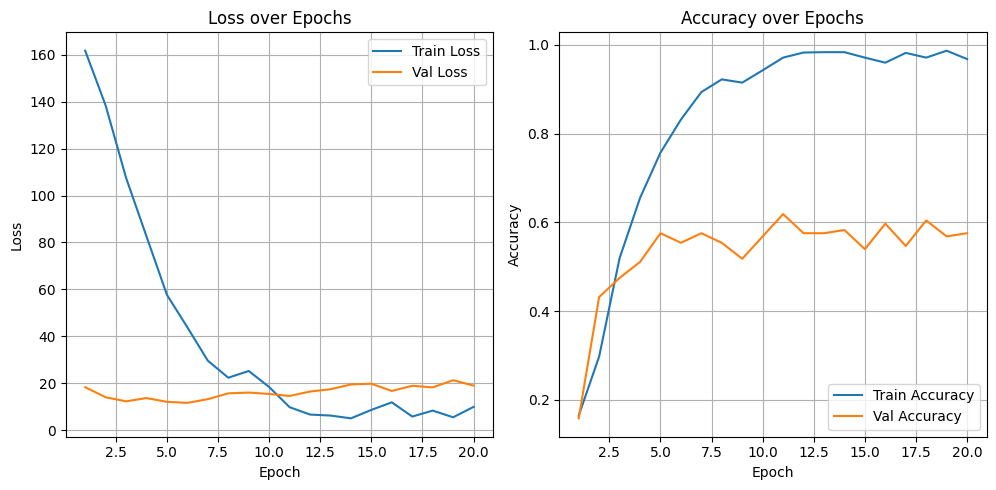

In [47]:
import matplotlib.pyplot as plt

epochs = range(1, 20 + 1)

plt.figure(figsize=(15, 5))

# Plot 1: Loss
plt.subplot(1, 3, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: Accuracy
plt.subplot(1, 3, 2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Get Test Results

In [48]:
from sklearn.metrics import accuracy_score, f1_score

def evaluate_model(model, dataloader, device, class_names=None):
    model.eval()  # Set the model to evaluation mode (no dropout, etc.)
    all_preds = []
    all_labels = []

    # Disable gradient calculations for faster inference
    with torch.no_grad():
        for batch in dataloader:
            # Move input tensors to the appropriate device (CPU or GPU)
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)

            # Labels stay on CPU for metric calculation
            labels = batch['labels'].cpu().numpy()

            # Forward pass
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)

            # Get predicted class indices
            preds = torch.argmax(outputs, dim=1).cpu().numpy()

            # Collect predictions and true labels
            all_preds.extend(preds)
            all_labels.extend(labels)

    # Compute metrics
    acc = accuracy_score(all_labels, all_preds)  # Overall accuracy
    f1_macro = f1_score(all_labels, all_preds, average='macro')  # Mean F1 across classes
    f1_per_class = f1_score(all_labels, all_preds, average=None)  # F1 for each class
    f1_std = f1_per_class.std()  # Standard deviation of F1 across classes

    # Print evaluation summary
    print(f"\nTest Results:")
    print(f"Accuracy:        {acc:.4f}")
    print(f"Mean F1-score:   {f1_macro:.4f}")
    print(f"F1 Std Dev:      {f1_std:.4f}")




In [49]:
evaluate_model(model, test_loader, device, class_names=le.classes_)


Test Results:
Accuracy:        0.5500
Mean F1-score:   0.5417
F1 Std Dev:      0.1071
